# Customer Churn Prediction Project

You are a Data Analyst working for an e-commerce company that wants to identify customers who are likely to churn.

The objective of this project is to explore customer behavior, prepare the data, train classification models, evaluate their performance, and interpret the business implications of the results.

## 1. Step 0: Import Libraries

Import all required libraries for data analysis, preprocessing, modeling, and evaluation.

Since this is a classification problem, you will use both Logistic Regression and Decision Tree models to compare their performance using different evaluation metrics.

In [1]:
# Library for data manipulation and analysis
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Splitting data into training and testing sets
from sklearn.model_selection import train_test_split

# Machine learning models for classification
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

# Evaluation metrics to measure model performance
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix

# Used to scale numerical features to a common range. More details on how to apply it will be provided in a later step.
from sklearn.preprocessing import StandardScaler

## 2. Task 1: Data Exploration

Explore the dataset to understand its structure, variables, and target distribution.

- Display the first rows of the dataset using `head()`
- Check data types and missing values using `info()`
- Identify missing values using `isnull().sum()`
- Analyze the target variable using `value_counts()` on `Churn`
- Generate summary statistics using `describe()`
- You are encouraged to explore the dataset further using additional functions

In [2]:
# Load dataset
df = pd.read_csv("https://practicum-content.s3.amazonaws.com/datasets/ecommerce_churn.csv")

# Display the first rows of the dataset
df.head()

,CustomerID,Churn,Tenure,Gender,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderCount,DaySinceLastOrder
0,54648,0,1.0,Female,4,Single,3,0,2.0,1.0
1,53504,1,3.0,Male,2,Married,9,0,NaN,6.0
2,50722,0,8.0,Male,4,Married,3,0,6.0,4.0
3,50745,0,19.0,Male,4,Divorced,6,0,1.0,3.0
4,53391,1,21.0,Male,3,Single,6,0,2.0,1.0


In [3]:
# Check data types and missing values
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1896 entries, 0 to 1895
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         1896 non-null   int64  
 1   Churn              1896 non-null   int64  
 2   Tenure             1771 non-null   float64
 3   Gender             1896 non-null   str    
 4   SatisfactionScore  1896 non-null   int64  
 5   MaritalStatus      1896 non-null   str    
 6   NumberOfAddress    1896 non-null   int64  
 7   Complain           1896 non-null   int64  
 8   OrderCount         1833 non-null   float64
 9   DaySinceLastOrder  1797 non-null   float64
dtypes: float64(3), int64(5), str(2)
memory usage: 148.3 KB


In [4]:
# Identify missing values in the dataset
df.isnull().sum()

CustomerID             0
Churn                  0
Tenure               125
Gender                 0
SatisfactionScore      0
MaritalStatus          0
NumberOfAddress        0
Complain               0
OrderCount            63
DaySinceLastOrder     99
dtype: int64

In [5]:
# Analyze the target variable (Churn)
print("Churn Value Counts:")
print(df["Churn"].value_counts())
print("\nChurn Proportions:")
print(df["Churn"].value_counts(normalize=True))

Churn Value Counts:
Churn
0    948
1    948
Name: count, dtype: int64

Churn Proportions:
Churn
0    0.5
1    0.5
Name: proportion, dtype: float64


In [6]:
# Generate summary statistics for numerical features
df.describe()

,CustomerID,Churn,Tenure,SatisfactionScore,NumberOfAddress,Complain,OrderCount,DaySinceLastOrder
count,1896.000000,1896.000000,1771.000000,1896.000000,1896.000000,1896.000000,1833.000000,1797.000000
mean,52758.544304,0.500000,7.629023,3.194093,4.313819,0.380802,2.905074,4.002782
std,1642.162800,0.500132,8.488319,1.366886,2.671286,0.485712,2.863286,3.653947
min,50001.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,0.000000
25%,51344.500000,0.000000,1.000000,2.000000,2.000000,0.000000,1.000000,1.000000
50%,52751.500000,0.500000,4.000000,3.000000,3.000000,0.000000,2.000000,3.000000
75%,54173.500000,1.000000,13.000000,4.000000,6.000000,1.000000,3.000000,7.000000
max,55630.000000,1.000000,61.000000,5.000000,22.000000,1.000000,16.000000,46.000000


Dataset shape: (1896, 10)
Duplicate rows: 0
Unique CustomerIDs: 1896

Churn rate by Complain:
          count      mean
Complain                 
0          1174  0.374787
1           722  0.703601

Churn rate by SatisfactionScore:
                   count      mean
SatisfactionScore                 
1                    341  0.392962
2                    173  0.427746
3                    585  0.499145
4                    371  0.495957
5                    426  0.619718

Churn rate by MaritalStatus:
               count      mean
MaritalStatus                 
Divorced         274  0.452555
Married          873  0.394044
Single           749  0.640854

Churn rate by Gender:
        count     mean
Gender                
Female    750  0.46400
Male     1146  0.52356

Tenure summary by Churn:
       count       mean  median
Churn                          
0        904  11.704646    10.0
1        867   3.379469     1.0

Early Tenure (<= 1 month) vs Tenure > 1 month Churn Rate:
Tenure <= 

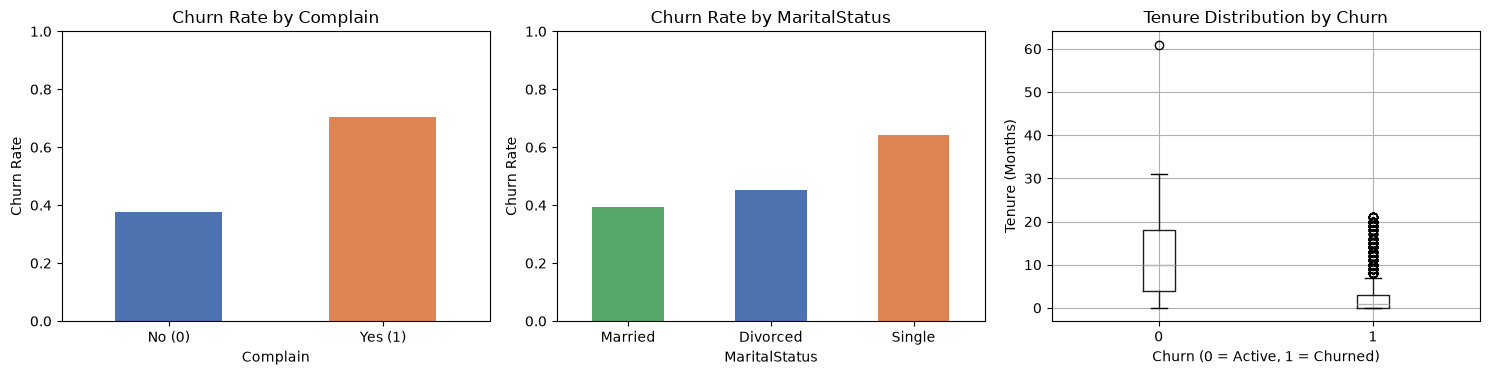

In [7]:
# (Optional) Use additional functions to explore the dataset further
print("Dataset shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
print("Unique CustomerIDs:", df["CustomerID"].nunique())

print("\nChurn rate by Complain:")
print(df.groupby("Complain")["Churn"].agg(["count", "mean"]))

print("\nChurn rate by SatisfactionScore:")
print(df.groupby("SatisfactionScore")["Churn"].agg(["count", "mean"]))

print("\nChurn rate by MaritalStatus:")
print(df.groupby("MaritalStatus")["Churn"].agg(["count", "mean"]))

print("\nChurn rate by Gender:")
print(df.groupby("Gender")["Churn"].agg(["count", "mean"]))

print("\nTenure summary by Churn:")
print(df.groupby("Churn")["Tenure"].agg(["count", "mean", "median"]))

print("\nEarly Tenure (<= 1 month) vs Tenure > 1 month Churn Rate:")
print("Tenure <= 1:", df[df["Tenure"] <= 1]["Churn"].agg(["count", "mean"]).to_dict())
print("Tenure > 1:", df[df["Tenure"] > 1]["Churn"].agg(["count", "mean"]).to_dict())

# Visualize key churn drivers
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

df.groupby("Complain")["Churn"].mean().plot(kind="bar", ax=axes[0], color=["#4C72B0", "#DD8452"])
axes[0].set_title("Churn Rate by Complain")
axes[0].set_xticklabels(["No (0)", "Yes (1)"], rotation=0)
axes[0].set_ylabel("Churn Rate")
axes[0].set_ylim(0, 1)

df.groupby("MaritalStatus")["Churn"].mean().sort_values().plot(kind="bar", ax=axes[1], color=["#55A868", "#4C72B0", "#DD8452"])
axes[1].set_title("Churn Rate by MaritalStatus")
axes[1].tick_params(axis="x", rotation=0)
axes[1].set_ylabel("Churn Rate")
axes[1].set_ylim(0, 1)

df.boxplot(column="Tenure", by="Churn", ax=axes[2])
axes[2].set_title("Tenure Distribution by Churn")
axes[2].set_xlabel("Churn (0 = Active, 1 = Churned)")
axes[2].set_ylabel("Tenure (Months)")
plt.suptitle("")
plt.tight_layout()
plt.show()

### Data Exploration Observations

- **Dataset Size & Integrity:** The dataset contains **1,896 rows and 10 columns** with **0 duplicate rows** and **1,896 unique `CustomerID` values**. Eight columns are numeric (`int64` / `float64`) and two are categorical (`Gender`, `MaritalStatus`).
- **Missing Values:** Only three numerical columns contain missing values: `Tenure` (**125 missing**, 6.59%), `DaySinceLastOrder` (**99 missing**, 5.22%), and `OrderCount` (**63 missing**, 3.32%). The target column `Churn` has **0 missing values**.
- **Balanced Target Variable:** `Churn` is perfectly balanced with **948 active customers (`0`, 50.0%)** and **948 churned customers (`1`, 50.0%)**.
- **Skewed Numerical Features:** `Tenure` (median `4.0`, mean `7.63`, max `61`), `OrderCount` (median `2.0`, mean `2.91`, max `16`), and `DaySinceLastOrder` (median `3.0`, mean `4.00`, max `46`) are all right-skewed with upper-tail outliers, which supports using **median imputation**.
- **Key Behavioral Signals:**
  - **Early Tenure:** Churned customers have a median tenure of **1.0 month** (mean `3.38`) compared to **10.0 months** (mean `11.70`) for active customers. Customers with `Tenure <= 1` month churned at **84.03%** (`n = 739`), compared to **23.84%** (`n = 1,032`) for `Tenure > 1` month.
  - **Complaints:** Customers who filed a complaint (`Complain = 1`) churned at **70.36%** (`n = 722`), nearly double the **37.48%** rate (`n = 1,174`) for customers without complaints.
  - **Marital Status & Satisfaction:** `Single` customers churned at **64.09%** (`n = 749`), higher than `Divorced` (**45.26%**) and `Married` (**39.40%**). Interestingly, churn rose across self-reported `SatisfactionScore` from **39.30%** (score 1) to **61.97%** (score 5), showing that survey scores alone do not capture churn risk.

## 3. Task 2: Data Preprocessing

Prepare the dataset before building the machine learning models.

Perform the following tasks:
- Handle missing values:
  - Remove rows with missing values in the `Churn` column using `dropna`.
  - Apply median imputation to `Tenure`, `SatisfactionScore`, `NumberOfAddress`, `OrderCount`, and `DaySinceLastOrder` using `fillna`.
- Encode categorical variables:
  - Apply one-hot encoding to `Gender` and `MaritalStatus` using `pd.get_dummies()`
  - Set `drop_first=True` to avoid redundancy by removing one category from each variable, preventing duplicate information in the dataset.
- Scale numerical features (applied after the train-test split in Step 4.1).
- Define the feature set `X` (excluding `CustomerID` and `Churn`) and target `y` (`Churn`).

In [8]:
# Remove missing values in target using dropna()
df = df.dropna(subset=["Churn"])

# Numerical columns
num_cols = [
    "Tenure",
    "SatisfactionScore",
    "NumberOfAddress",
    "OrderCount",
    "DaySinceLastOrder"
]

# Apply median imputation to each numerical column using fillna()
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

print("Missing values after preprocessing:")
print(df.isnull().sum())

Missing values after preprocessing:
CustomerID           0
Churn                0
Tenure               0
Gender               0
SatisfactionScore    0
MaritalStatus        0
NumberOfAddress      0
Complain             0
OrderCount           0
DaySinceLastOrder    0
dtype: int64


In [9]:
# Identify categorical variables
categorical_cols = ["Gender", "MaritalStatus"]

# Apply One-Hot Encoding using pd.get_dummies()
df_encoded = pd.get_dummies(
    df,
    columns=categorical_cols,
    drop_first=True
)

df_encoded

,CustomerID,Churn,Tenure,SatisfactionScore,NumberOfAddress,Complain,OrderCount,DaySinceLastOrder,Gender_Male,MaritalStatus_Married,MaritalStatus_Single
0,54648,0,1.0,4,3,0,2.0,1.0,False,False,True
1,53504,1,3.0,2,9,0,2.0,6.0,True,True,False
2,50722,0,8.0,4,3,0,6.0,4.0,True,True,False
3,50745,0,19.0,4,6,0,1.0,3.0,True,False,False
4,53391,1,21.0,3,6,0,2.0,1.0,True,False,True
...,...,...,...,...,...,...,...,...,...,...,...
1891,51413,0,18.0,5,3,0,1.0,0.0,True,True,False
1892,55179,0,10.0,1,3,0,2.0,9.0,True,False,True
1893,55053,1,1.0,4,3,1,2.0,1.0,False,False,True
1894,53103,0,20.0,3,4,0,2.0,9.0,False,True,False


In [10]:
# Define Features by removing the target variable and the customer identifier
X = df_encoded.drop(["Churn", "CustomerID"], axis=1)

# Define Target
y = df_encoded["Churn"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1896, 9)
y shape: (1896,)


### Preprocessing Rationale

- **Median Imputation:** `Tenure` (median `4.0`), `OrderCount` (median `2.0`), and `DaySinceLastOrder` (median `3.0`) exhibit strong right skewness and high-end outliers (maximums of `61`, `16`, and `46`, respectively). Using the **median** instead of the mean prevents outliers from pulling imputed values upward and keeps all **1,896** records intact without missing entries.
- **One-Hot Encoding with `drop_first=True`:** Converting `Gender` and `MaritalStatus` into binary indicator columns allows scikit-learn models to process categorical data numerically. Setting `drop_first=True` drops one reference category per variable (`Gender_Female` and `MaritalStatus_Divorced`), avoiding redundant, perfectly collinear dummy columns (the dummy variable trap) that would otherwise duplicate information and destabilize Logistic Regression coefficients.
- **Excluding `CustomerID`:** `CustomerID` is an arbitrary identifier with no behavioral signal, so dropping it leaves **9** predictive features in `X` (`(1896, 9)`) aligned with `y` (`(1896,)`).

## 4. Task 3: Train-Test Split

Split the dataset into training and testing subsets.

Perform the following tasks:
- Ensure `train_test_split` is imported in Step 0 before splitting the dataset
- Split the data into training and testing sets
- Use `test_size=0.20`
- Use `random_state=42` to ensure reproducible results
- Display the shapes of `X_train`, `X_test`, `y_train`, and `y_test`
- Apply feature scaling to the training and testing sets using `StandardScaler`.

In [11]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Display dataset shapes
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (1516, 9)
X_test shape: (380, 9)
y_train shape: (1516,)
y_test shape: (380,)


### 4.1. Feature Scaling

In this step, you will apply feature scaling to the dataset. As you saw in previous lessons, numerical variables should be on the same scale when using many machine learning algorithms. This is important because features with larger values can dominate the model and affect its performance.

Unlike some basic models where scaling is less critical, in classification algorithms such as Logistic Regression and Decision Trees, scaling helps ensure that the model learns patterns more effectively from all features.

To perform this, execute the following lines of code:

In [12]:
# Scale numerical features
scaler = StandardScaler()

# Create copies to avoid modifying original data directly
X_train = X_train.copy()
X_test = X_test.copy()

# Learn scaling parameters from the training data and apply the transformation
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])

# Apply the same transformation to test data
X_test[num_cols] = scaler.transform(X_test[num_cols])

## 5. Task 4: Train Classification Models

Train classification models using the training dataset.

Perform the following tasks:
- **Logistic Regression:** Create a Logistic Regression model with `max_iter=1000`, fit on `X_train` and `y_train`, and generate predictions on `X_test`.
- **Decision Tree:** Experiment with different values of `max_depth` (e.g., `3`, `4`, and `5`, as well as `2`, `6`, and `None` for comparison), analyze how model performance changes, select the depth that gives the best balance of high Recall and low overfitting, fit on `X_train` and `y_train`, and generate predictions on `X_test`.

In [13]:
# Logistic Regression
# Initialize Logistic Regression model (use max_iter)
log_model = LogisticRegression(max_iter=1000, random_state=42)

# Train the model using the training data
log_model.fit(X_train, y_train)

# Generate predictions on the test set
y_pred_log = log_model.predict(X_test)

In [14]:
# Experiment with different max_depth values for the Decision Tree Classifier
depth_candidates = [2, 3, 4, 5, 6, None]
depth_results = []

for depth in depth_candidates:
    dt_exp = DecisionTreeClassifier(max_depth=depth, random_state=42)
    dt_exp.fit(X_train, y_train)
    y_pred_exp = dt_exp.predict(X_test)
    train_acc = dt_exp.score(X_train, y_train)
    test_acc = accuracy_score(y_test, y_pred_exp)
    depth_results.append({
        "max_depth": str(depth),
        "Train Accuracy": round(train_acc, 4),
        "Test Accuracy": round(test_acc, 4),
        "Train-Test Gap": round(train_acc - test_acc, 4),
        "Precision": round(precision_score(y_test, y_pred_exp), 4),
        "Recall": round(recall_score(y_test, y_pred_exp), 4),
    })

depth_df = pd.DataFrame(depth_results)
depth_df

,max_depth,Train Accuracy,Test Accuracy,Train-Test Gap,Precision,Recall
0,2,0.7658,0.7632,0.0027,0.8438,0.675
1,3,0.8015,0.8132,-0.0117,0.8377,0.800
2,4,0.8226,0.7974,0.0252,0.7860,0.845
3,5,0.8417,0.8026,0.0391,0.8453,0.765
4,6,0.8542,0.8263,0.0279,0.8454,0.820
5,None,0.9901,0.8947,0.0954,0.8670,0.945


### `max_depth` Selection Justification

Comparing the candidate depths highlights the classic bias–variance tradeoff:

- **`max_depth=2`:** Underfits the training data, producing the lowest Test Accuracy (`0.7632`) and lowest Recall (`0.6750`).
- **`max_depth=3`:** Generalizes well (Train–Test Gap `-0.0117`) with Test Accuracy `0.8132`, but achieves lower Recall (`0.8000`) than `max_depth=4`.
- **`max_depth=4` (Selected):** Achieves the **highest Recall (`0.8450`)** among all constrained depths (`2` through `6`) while keeping the Train–Test Gap moderate (`0.8226 - 0.7974 = 0.0252`, well below the `> 0.05` overfitting threshold).
- **`max_depth=5` and `6`:** Show larger train–test gaps (`0.0391` and `0.0279`) and lower Recall (`0.7650` and `0.8200`) than `max_depth=4`.
- **`max_depth=None`:** Memorizes the training set (`0.9901` Train Accuracy vs. `0.8947` Test Accuracy), creating a large `0.0954` overfitting gap (`> 0.05`).

Because churn retention prioritizes **Recall** while controlling overfitting, **`max_depth=4`** is selected for the Decision Tree model.

In [15]:
# Decision Tree Classifier
# Initialize Decision Tree Classifier: use max_depth to control the complexity of the tree (helps prevent overfitting) and
# random_state ensures reproducible results
tree_model = DecisionTreeClassifier(max_depth=4, random_state=42)

# Train the model using the training data
tree_model.fit(X_train, y_train)

# Generate predictions on the test set
y_pred_tree = tree_model.predict(X_test)

## 6. Task 5: Model Evaluation

Evaluate the performance of both models.

Perform the following tasks:
- Calculate Accuracy using the test set predictions.
- Calculate Precision using the test set predictions.
- Calculate Recall using the test set predictions (Use Recall as the primary metric when selecting the best model for customer churn prediction.)
- Generate a Confusion Matrix
- Compare the results of both models
- Compare training and test performance for the models to analyze potential overfitting or underfitting by executing the cells below.

There is no strict rule to define overfitting, but the following guideline can help interpret the difference between training and test performance:

| Difference | Interpretation |
|---|---|
| `< 0.02` | Small difference (likely noise) |
| `0.02 – 0.05` | Moderate difference (may be relevant) |
| `> 0.05` | Large difference (possible overfitting) |

If the difference is small, the model is well generalized. Prefer that model, especially if it also has higher Recall.

In [16]:
# Logistic Regression Evaluation
print("Logistic Regression Performance")
print()
print("Accuracy:", accuracy_score(y_test, y_pred_log))
print("Precision:", precision_score(y_test, y_pred_log))
print("Recall:", recall_score(y_test, y_pred_log))
print()
print("Confusion Matrix")
print(confusion_matrix(y_test, y_pred_log))

Logistic Regression Performance

Accuracy: 0.8052631578947368
Precision: 0.794392523364486
Recall: 0.85

Confusion Matrix
[[136  44]
 [ 30 170]]


### 6.1. Overfitting Check (Train vs Test Performance - Logistic Regression)

No additional code is required. Execute the cells below and interpret the results.

In [17]:
# Logistic Regression comparison
# Compare training vs test accuracy to check for overfitting or underfitting
# The .score() method returns accuracy for classification models
train_acc_log = log_model.score(X_train, y_train)
test_acc_log = log_model.score(X_test, y_test)

print("Logistic Regression Performance Comparison")
print("-------------------------------")
# Accuracy is used here to check how well the model performs on seen vs unseen data
print("Train Accuracy:", train_acc_log)
print("Test Accuracy:", test_acc_log)
print()
print("Difference (Train - Test):", train_acc_log - test_acc_log)

Logistic Regression Performance Comparison
-------------------------------
Train Accuracy: 0.8139841688654353
Test Accuracy: 0.8052631578947368

Difference (Train - Test): 0.00872101097069855


#### Logistic Regression Generalization Interpretation

- **Train vs. Test Gap:** Train Accuracy is **0.8140** (`81.40%`) and Test Accuracy is **0.8053** (`80.53%`), yielding a difference of **0.0087** (`0.87` percentage points).
- **Guideline Assessment:** Because `0.0087 < 0.02`, this is a **small difference (likely noise)**. The model neither overfits nor underfits and generalizes reliably to unseen customers.
- **Confusion Matrix Breakdown (`[[136, 44], [30, 170]]`):** Out of **200** actual churned customers in the test set, Logistic Regression correctly identifies **170** (True Positives) and misses **30** (False Negatives). Out of **180** active customers, it correctly classifies **136** (True Negatives) and flags **44** as false alarms (False Positives).

In [18]:
# Decision Tree Evaluation
print("Decision Tree Performance")
print()
print("Accuracy:", accuracy_score(y_test, y_pred_tree))
print("Precision:", precision_score(y_test, y_pred_tree))
print("Recall:", recall_score(y_test, y_pred_tree))
print()
print("Confusion Matrix")
print(confusion_matrix(y_test, y_pred_tree))

Decision Tree Performance

Accuracy: 0.7973684210526316
Precision: 0.786046511627907
Recall: 0.845

Confusion Matrix
[[134  46]
 [ 31 169]]


### 6.2. Overfitting Check (Train vs Test Performance - Decision Tree)

No additional code is required. Execute the cells below and interpret the results.

In [19]:
# Train vs Test performance - Decision Tree
train_accuracy = tree_model.score(X_train, y_train)
test_accuracy = tree_model.score(X_test, y_test)

print("Decision Tree Performance Comparison")
print("-------------------------------")
print("Train Accuracy:", train_accuracy)
print("Test Accuracy:", test_accuracy)
print()
print("Difference (Train - Test):", train_accuracy - test_accuracy)

Decision Tree Performance Comparison
-------------------------------
Train Accuracy: 0.8225593667546174
Test Accuracy: 0.7973684210526316

Difference (Train - Test): 0.025190945701985767


#### Decision Tree Generalization Interpretation

- **Train vs. Test Gap:** Train Accuracy is **0.8226** (`82.26%`) and Test Accuracy is **0.7974** (`79.74%`), giving a difference of **0.0252** (`2.52` percentage points).
- **Guideline Assessment:** Because `0.0252` falls in the **`0.02 – 0.05`** range, this is a **moderate difference**. Limiting the tree to `max_depth=4` prevented severe overfitting, though the tree exhibits slightly higher variance on unseen data than Logistic Regression (`0.0087` gap).
- **Confusion Matrix Breakdown (`[[134, 46], [31, 169]]`):** Out of **200** churned customers in the test set, the Decision Tree correctly flags **169** (True Positives) and misses **31** (False Negatives), while producing **46** False Positives out of **180** active customers.

### 6.3. Compare model performance

Compare the performance of both models using Accuracy, Precision, and Recall.

Select the best model based on the highest Recall, since in customer churn prediction it is more important to correctly identify customers who are likely to leave the company than to minimize other types of errors.

In [20]:
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_log),
        accuracy_score(y_test, y_pred_tree)
    ],
    "Precision": [
        precision_score(y_test, y_pred_log),
        precision_score(y_test, y_pred_tree)
    ],
    "Recall": [
        recall_score(y_test, y_pred_log),
        recall_score(y_test, y_pred_tree)
    ]
})

comparison

,Model,Accuracy,Precision,Recall
0,Logistic Regression,0.805263,0.794393,0.850
1,Decision Tree,0.797368,0.786047,0.845


In [21]:
# Inspect top feature drivers across both models
feature_drivers = pd.DataFrame({
    "Feature": X.columns,
    "LogReg_Coefficient": log_model.coef_[0].round(4),
    "LogReg_Odds_Ratio": np.exp(log_model.coef_[0]).round(2),
    "Tree_Importance": tree_model.feature_importances_.round(4),
}).sort_values(by="Tree_Importance", ascending=False)

feature_drivers

,Feature,LogReg_Coefficient,LogReg_Odds_Ratio,Tree_Importance
0,Tenure,-1.5835,0.21,0.7190
3,Complain,1.6705,5.31,0.1198
2,NumberOfAddress,0.4988,1.65,0.0742
5,DaySinceLastOrder,-0.4256,0.65,0.0408
1,SatisfactionScore,0.3483,1.42,0.0211
4,OrderCount,0.4499,1.57,0.0210
6,Gender_Male,0.2974,1.35,0.0022
7,MaritalStatus_Married,-0.4677,0.63,0.0018
8,MaritalStatus_Single,0.4327,1.54,0.0000


### Model Comparison & Selection Analysis

- **Metric-by-Metric Winner:** **Logistic Regression** outperforms the `max_depth=4` Decision Tree on every evaluation metric:
  - **Recall (Primary Metric):** **0.8500** (`85.00%`) vs. **0.8450** (`84.50%`)
  - **Accuracy:** **0.8053** (`80.53%`) vs. **0.7974** (`79.74%`)
  - **Precision:** **0.7944** (`79.44%`) vs. **0.7860** (`78.60%`)
- **Generalization Winner:** Logistic Regression has a **small** train–test gap (`0.0087`, `< 0.02`), whereas the Decision Tree has a **moderate** gap (`0.0252`, `0.02–0.05`).
- **Which model catches more churners, and at what cost?**
  - **Logistic Regression catches more churners (`170` vs. `169` out of `200`, missing `30` instead of `31`)** while incurring **lower false-positive cost** (`44` false positives vs. `46` for the Decision Tree, yielding higher Precision of `0.7944` vs. `0.7860`).
  - Its cost of **44 False Positives** means sending low-cost retention outreach (e.g., check-in emails or modest loyalty incentives) to 44 active customers who would have stayed anyway — a much smaller business cost than losing customers through False Negatives.

Based on achieving the **highest Recall (`0.8500`)**, superior Precision and Accuracy, and the smallest generalization gap (`0.0087`), **Logistic Regression** is selected as the best model.

## 7. Conclusion

The **Logistic Regression** model achieved the highest Recall and was selected as the best model for this project.

- **Accuracy:** 0.8053
- **Precision:** 0.7944
- **Recall:** 0.8500

Recall was considered the most important metric because the main objective of churn prediction is to identify customers who are likely to leave the company.

### Summary of Model Results & Why Logistic Regression Performed Best
On the held-out test set (`n = 380`: 200 churned, 180 active), **Logistic Regression** outperformed the regularized Decision Tree (`max_depth=4`) across all metrics: **Recall (`0.8500` vs. `0.8450`)**, **Accuracy (`0.8053` vs. `0.7974`)**, and **Precision (`0.7944` vs. `0.7860`)**. It correctly captured **170 of 200 churners** (30 missed) with **44 false positives** (compared to 169 caught and 46 false positives for the Decision Tree).

Logistic Regression performed best for three reasons:
1. **Superior Generalization:** Its train–test accuracy difference is only **0.0087** (`0.8140` train vs. `0.8053` test), a small gap well below `0.02`, compared to the Decision Tree's moderate **0.0252** gap (`0.8226` train vs. `0.7974` test).
2. **Additive Risk Structure:** Churn in this dataset is strongly shaped by cumulative linear effects (short tenure combined with complaints and demographic/order signals), which Logistic Regression captures smoothly without brittle axis-aligned splits.
3. **Actionable Probability Outputs:** Logistic Regression produces calibrated risk probabilities (`predict_proba`), allowing the retention team to rank customers by churn risk and tune outreach thresholds to campaign budgets.

### Key Churn Drivers
Both exploratory analysis and model weights point to the same primary drivers of churn:
- **Early Tenure (`Tenure`):** Strongest protective factor (LogReg standardized coefficient **`-1.5835`**, odds ratio **`0.21`**, Tree importance **`71.90%`**). Customers in their first month (`Tenure <= 1`) churned at **84.03%** (`n = 739`), versus **23.84%** (`n = 1,032`) after month 1. Median tenure was **1.0 month** for churned customers vs. **10.0 months** for active customers.
- **Customer Complaints (`Complain`):** Strongest risk multiplier (LogReg coefficient **`+1.6705`**, odds ratio **`5.31x`**, Tree importance **`11.98%`**). Customers who filed a complaint churned at **70.36%** vs. **37.48%** for non-complainers.
- **Marital Status & Behavioral Signals:** `Single` customers churned at **64.09%** (`MaritalStatus_Single` coef **`+0.4327`**) compared with **39.40%** for `Married` customers (`MaritalStatus_Married` coef **`-0.4677`**). Higher `NumberOfAddress` (`+0.4988`) and `OrderCount` (`+0.4499`) were also positively associated with churn when controlling for tenure, while `SatisfactionScore` alone was unreliable (score 5 still experienced **61.97%** churn).

### Business Implications & Recommendations
1. **Prioritize First-30-Day Onboarding (`Tenure <= 1` month):** With **84.03%** churn in month 1, trigger automated onboarding sequences, proactive customer-success check-ins, and a second-order incentive within the first 14–21 days to help new buyers establish repeat habits.
2. **Escalate Complaints Immediately (`Complain = 1`):** Because complaints carry **5.31x** churn odds (`70.36%` churn rate), route every complaint into a fast-track resolution SLA followed by a proactive retention touchpoint or goodwill credit.
3. **Tailor Retention Offers for Single Shoppers:** Target the high-churn `Single` segment (`64.09%` churn) with personalized product recommendations and convenient multi-item bundles.
4. **Deploy Risk-Tiered Outreach Instead of Relying on Surveys Alone:** Score active accounts weekly using the Logistic Regression model — reserve high-touch retention offers for high-probability accounts and low-cost automated lifecycle emails for moderate-risk accounts — ensuring the **44** false-positive touchpoints remain inexpensive while preventing costly lost customers.